# PredictGuard AI — Phase 4: Ensemble Learning
**Covers Practical 05 — Stacking, AdaBoost, Voting**

Dataset: AI4I 2020 Predictive Maintenance | Target: `Machine failure` (0 = no failure, 1 = failure)

Uses the same split, preprocessing and base classifiers as Phase 3, so ensemble results are directly comparable. Run every cell top to bottom.

## Step 1 — Load the AI4I dataset

In [ ]:
!wget -q "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip" -O ai4i.zip
!unzip -o -q ai4i.zip -d /content/ai4i_data
!ls /content/ai4i_data

ai4i2020.csv


In [ ]:
import pandas as pd
df = pd.read_csv("/content/ai4i_data/ai4i2020.csv")
print(df.shape)
print(df["Machine failure"].value_counts())

(10000, 14)
Machine failure
0    9661
1     339
Name: count, dtype: int64


## Step 2 — Preprocessing (identical to Phase 3)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

feature_cols = ["Type", "Air temperature [K]", "Process temperature [K]",
                "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
TARGET = "Machine failure"

X = df[feature_cols]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_features = ["Air temperature [K]", "Process temperature [K]",
                    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
categorical_features = ["Type"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first"), categorical_features),
])

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train failure rate: {y_train.mean()*100:.2f}%, Test failure rate: {y_test.mean()*100:.2f}%")

Train: (8000, 6), Test: (2000, 6)
Train failure rate: 3.39%, Test failure rate: 3.40%


## Step 3 — Baselines: the four individual classifiers from Phase 4/Practical 04
These are the benchmark the ensembles must beat. They are also the base learners for Voting and Stacking.

In [ ]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier, AdaBoostClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss)
import numpy as np
import matplotlib.pyplot as plt

results = {}
trained_models = {}
preds = {}
probs = {}

def build_and_evaluate(name, classifier, show_report=True):
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", classifier)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "LogLoss": log_loss(y_test, pipe.predict_proba(X_test)),
    }
    trained_models[name] = pipe
    preds[name] = y_pred
    probs[name] = y_prob

    if show_report:
        print(f"\n--- {name} ---")
        print(classification_report(y_test, y_pred, target_names=["No Failure", "Failure"], zero_division=0))
    return pipe

In [ ]:
# Base learners (same hyperparameters as Phase 3)
def make_svm(): return SVC(kernel="rbf", probability=True, random_state=42)
def make_dt():  return DecisionTreeClassifier(random_state=42, max_depth=8)
def make_knn(): return KNeighborsClassifier(n_neighbors=5)
def make_nb():  return GaussianNB()

build_and_evaluate("SVM", make_svm())
build_and_evaluate("Decision Tree", make_dt())
build_and_evaluate("KNN", make_knn())
build_and_evaluate("Naive Bayes", make_nb())


--- SVM ---
              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.87      0.19      0.31        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.65      2000
weighted avg       0.97      0.97      0.96      2000


--- Decision Tree ---
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1932
     Failure       0.84      0.68      0.75        68

    accuracy                           0.98      2000
   macro avg       0.91      0.84      0.87      2000
weighted avg       0.98      0.98      0.98      2000


--- KNN ---
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.83      0.28      0.42        68

    accuracy                           0.97      2000
   macro avg       0.90      0.64      0.70      2000
weighted avg       0.97  

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['Type'])])),
                ('classifier', GaussianNB())])

## Step 4 — Ensemble Models

### 4a. Voting Classifier
Hard voting = majority class vote. Soft voting = average of predicted probabilities (usually better when the base models give calibrated probabilities).

In [ ]:
estimators = [("svm", make_svm()), ("dt", make_dt()), ("knn", make_knn()), ("nb", make_nb())]

# Hard voting has no predict_proba, so evaluate it separately
hard_vote = Pipeline([("preprocessor", preprocessor),
                      ("classifier", VotingClassifier(estimators=estimators, voting="hard"))])
hard_vote.fit(X_train, y_train)
yp = hard_vote.predict(X_test)
results["Voting (Hard)"] = {
    "Accuracy": accuracy_score(y_test, yp),
    "Precision": precision_score(y_test, yp, zero_division=0),
    "Recall": recall_score(y_test, yp, zero_division=0),
    "F1": f1_score(y_test, yp, zero_division=0),
    "ROC-AUC": np.nan, "LogLoss": np.nan,
}
trained_models["Voting (Hard)"] = hard_vote
preds["Voting (Hard)"] = yp
print("\n--- Voting (Hard) ---")
print(classification_report(y_test, yp, target_names=["No Failure", "Failure"], zero_division=0))

build_and_evaluate("Voting (Soft)", VotingClassifier(estimators=estimators, voting="soft"))


--- Voting (Hard) ---
              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.85      0.16      0.27        68

    accuracy                           0.97      2000
   macro avg       0.91      0.58      0.63      2000
weighted avg       0.97      0.97      0.96      2000


--- Voting (Soft) ---
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.84      0.38      0.53        68

    accuracy                           0.98      2000
   macro avg       0.91      0.69      0.76      2000
weighted avg       0.97      0.98      0.97      2000



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['Type'])])),
                ('classifier',
                 VotingClassifier(estimators=[('svm',
                                               SVC(probability=True,
                                                   random_state=42)),
                                              ('dt',
                                               DecisionTreeClassifier(max_depth=8,
                                                                      random_state=42)),
                                              ('knn', KNeighborsClassifier()),
                                              ('nb', GaussianNB())],
                                  voting='soft'))])

### 4b. AdaBoost
Boosting trains weak learners sequentially, each focusing on the examples the previous ones got wrong. Shallow trees are the standard weak learner.

In [ ]:
build_and_evaluate("AdaBoost (stumps)", AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200,
    learning_rate=0.5, random_state=42))

build_and_evaluate("AdaBoost (depth=3)", AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3), n_estimators=100,
    learning_rate=0.5, random_state=42))


--- AdaBoost (stumps) ---
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.80      0.29      0.43        68

    accuracy                           0.97      2000
   macro avg       0.89      0.65      0.71      2000
weighted avg       0.97      0.97      0.97      2000


--- AdaBoost (depth=3) ---
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.80      0.60      0.69        68

    accuracy                           0.98      2000
   macro avg       0.90      0.80      0.84      2000
weighted avg       0.98      0.98      0.98      2000



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['Type'])])),
                ('classifier',
                 AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3),
                                    learning_rate=0.5, n_estimators=100,
                                    random_state=42))])

### 4c. Stacking
Base learners' out-of-fold predictions become the input features of a meta-classifier (Logistic Regression), which learns how much to trust each base model.

In [ ]:
stack_estimators = [("svm", make_svm()), ("dt", make_dt()), ("knn", make_knn()), ("nb", make_nb())]

build_and_evaluate("Stacking", StackingClassifier(
    estimators=stack_estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5, stack_method="predict_proba", n_jobs=-1))


--- Stacking ---
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1932
     Failure       0.85      0.59      0.70        68

    accuracy                           0.98      2000
   macro avg       0.92      0.79      0.84      2000
weighted avg       0.98      0.98      0.98      2000



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['Type'])])),
                ('classifier',
                 StackingClassifier(cv=5,
                                    estimators=[('svm',
                                                 SVC(probability=True,
                                                     random_state=42)),
                                                ('dt',
                                                 DecisionTreeClassifier(max_depth=8,
                                                                        random_state=42)),
                                                ('knn', KNeighborsClassifier()),
                                                ('nb', GaussianNB())],
                                    final_estimator=LogisticRegression(max_iter=1000,
                                                                       random_state=42),
                                    n_jobs=-1, stack_method='predict_proba'))])

## Step 5 — Comparative Analysis: ensembles vs individual models

In [ ]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values("Recall", ascending=False)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(results_df)
results_df.to_csv("/content/ensemble_comparison.csv")
print("\nSorted by Recall (a missed failure is the costliest error in predictive maintenance)")

                    Accuracy  Precision  Recall     F1  ROC-AUC  LogLoss
Decision Tree         0.9845     0.8364  0.6765 0.7480   0.8743   0.2213
AdaBoost (depth=3)    0.9815     0.8039  0.6029 0.6891   0.9760   0.3006
Stacking              0.9825     0.8511  0.5882 0.6957   0.9694   0.0627
Voting (Soft)         0.9765     0.8387  0.3824 0.5253   0.9655   0.0658
AdaBoost (stumps)     0.9735     0.8000  0.2941 0.4301   0.9496   0.4197
KNN                   0.9735     0.8261  0.2794 0.4176   0.8368   0.3974
SVM                   0.9715     0.8667  0.1912 0.3133   0.9457   0.0799
Voting (Hard)         0.9705     0.8462  0.1618 0.2716      NaN      NaN
Naive Bayes           0.9570     0.2353  0.1176 0.1569   0.8841   0.1374

Sorted by Recall (a missed failure is the costliest error in predictive maintenance)


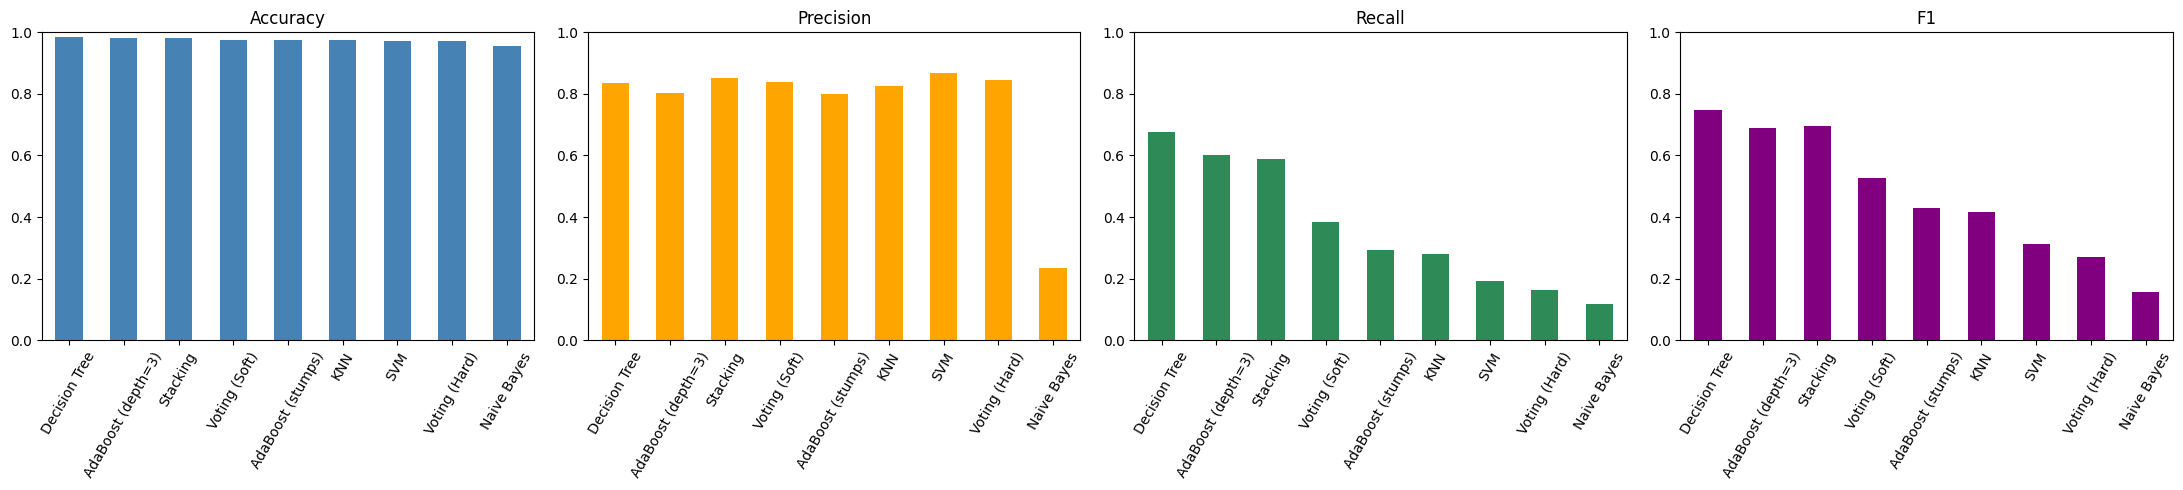

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
metrics = ["Accuracy", "Precision", "Recall", "F1"]
colors = ["steelblue", "orange", "seagreen", "purple"]
for ax, metric, color in zip(axes, metrics, colors):
    results_df[metric].plot(kind="bar", ax=ax, color=color, title=metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig("/content/ensemble_comparison_chart.png", dpi=120)
plt.show()

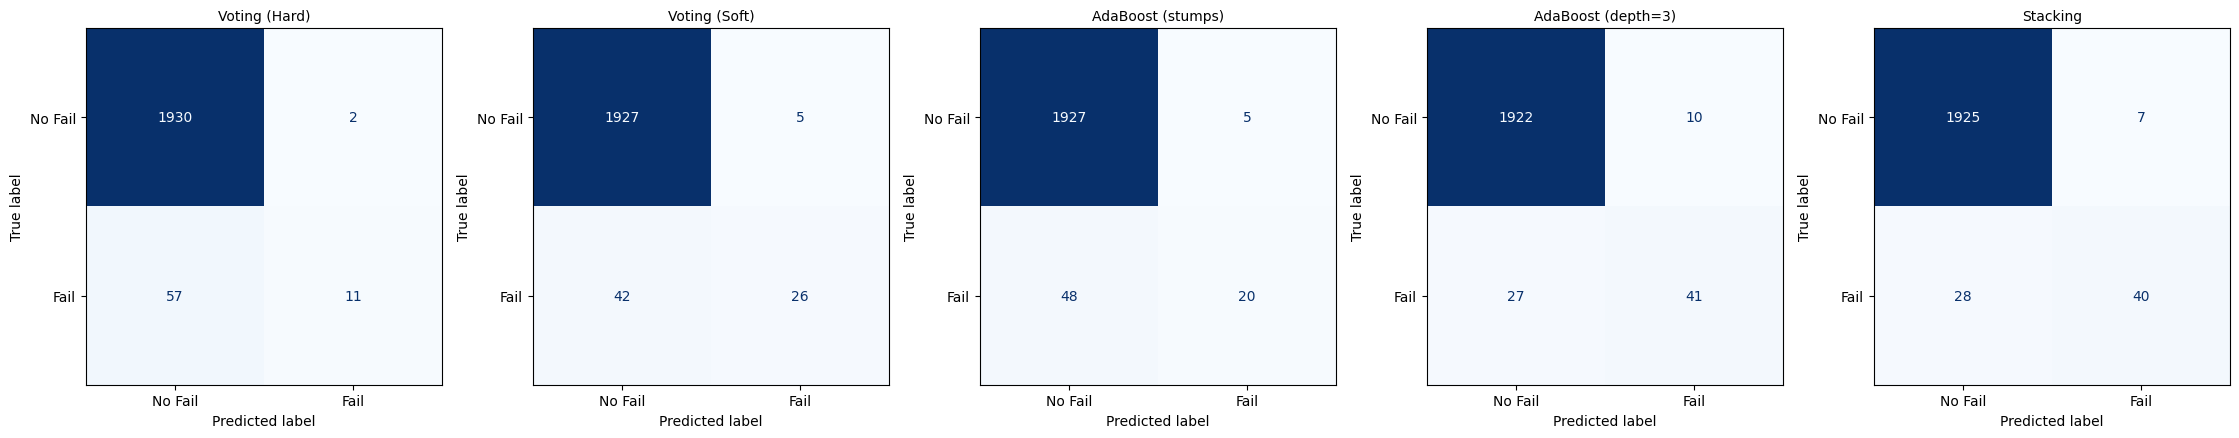

In [ ]:
# Confusion matrices for the ensembles
ens_names = ["Voting (Hard)", "Voting (Soft)", "AdaBoost (stumps)", "AdaBoost (depth=3)", "Stacking"]
fig, axes = plt.subplots(1, len(ens_names), figsize=(4.5*len(ens_names), 4.5))
for ax, name in zip(axes, ens_names):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["No Fail", "Fail"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.savefig("/content/ensemble_confusion_matrices.png", dpi=120)
plt.show()

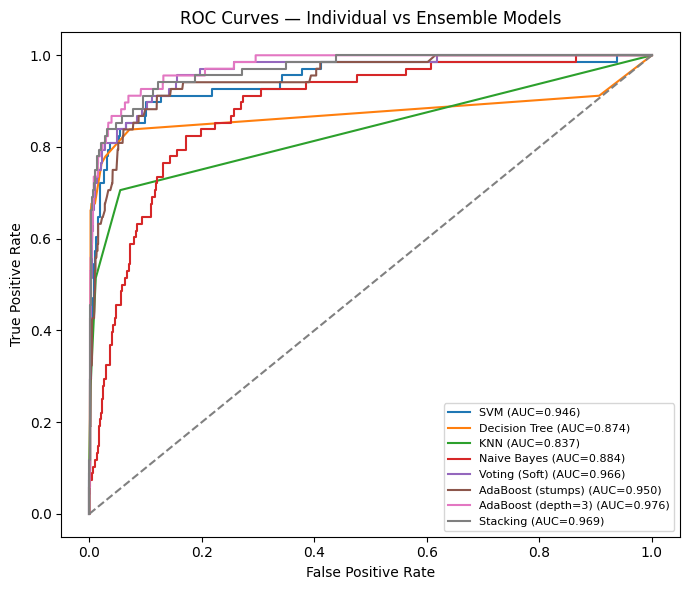

In [ ]:
# ROC curves (all models that output probabilities)
from sklearn.metrics import roc_curve
plt.figure(figsize=(7, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Individual vs Ensemble Models")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("/content/ensemble_roc.png", dpi=120)
plt.show()

## Step 6 — Diversity Analysis
Practical 05 asks how base-classifier diversity affects ensemble performance. Below: the pairwise **disagreement rate** between base learners (fraction of test samples where two models predict differently). Higher disagreement = more diverse = more room for an ensemble to improve on its members.

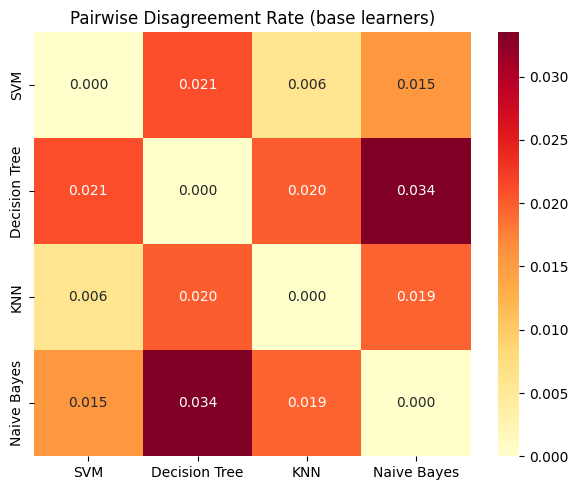

Failures in test set: 68
Caught by at least one base model: 48  (upper bound for simple voting-style ensembles)


In [ ]:
import seaborn as sns
base_names = ["SVM", "Decision Tree", "KNN", "Naive Bayes"]
dis = pd.DataFrame(index=base_names, columns=base_names, dtype=float)
for a in base_names:
    for b in base_names:
        dis.loc[a, b] = np.mean(preds[a] != preds[b])

plt.figure(figsize=(6, 5))
sns.heatmap(dis, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("Pairwise Disagreement Rate (base learners)")
plt.tight_layout()
plt.savefig("/content/diversity_heatmap.png", dpi=120)
plt.show()

# Oracle: how many true failures does AT LEAST ONE base model catch?
fail_idx = np.where(y_test.values == 1)[0]
caught_any = np.zeros(len(fail_idx), dtype=bool)
for n in base_names:
    caught_any |= (preds[n][fail_idx] == 1)
print(f"Failures in test set: {len(fail_idx)}")
print(f"Caught by at least one base model: {caught_any.sum()}  (upper bound for simple voting-style ensembles)")

## Step 7 — Threshold Tuning for Higher Recall (bonus)
Failures are only ~3.4% of the data, so the default 0.5 threshold misses many of them. We pick the threshold on the **training set** using cross-validated probabilities (no test-set leakage), then apply it to the test set.

Tuning threshold for: Stacking
Chosen threshold (max F2 on train CV): 0.053

--- Stacking @ threshold 0.053 ---
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.66      0.75      0.70        68

    accuracy                           0.98      2000
   macro avg       0.83      0.87      0.85      2000
weighted avg       0.98      0.98      0.98      2000



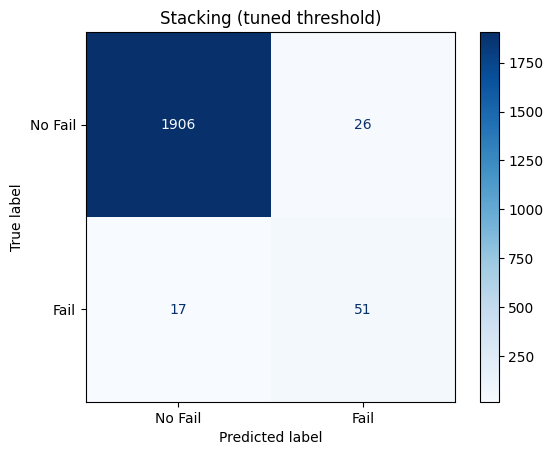

In [ ]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve
from sklearn.base import clone

soft_candidates = ["Voting (Soft)", "AdaBoost (depth=3)", "Stacking"]
best_name = max(soft_candidates, key=lambda n: results[n]["F1"])
print("Tuning threshold for:", best_name)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_prob = cross_val_predict(clone(trained_models[best_name]), X_train, y_train,
                            cv=skf, method="predict_proba", n_jobs=-1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, cv_prob)
beta = 2  # F2 weights recall twice as much as precision
f2 = (1 + beta**2) * prec[:-1] * rec[:-1] / (beta**2 * prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f2)]
print(f"Chosen threshold (max F2 on train CV): {best_thr:.3f}")

tuned_pred = (probs[best_name] >= best_thr).astype(int)
print(f"\n--- {best_name} @ threshold {best_thr:.3f} ---")
print(classification_report(y_test, tuned_pred, target_names=["No Failure", "Failure"], zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y_test, tuned_pred),
                       display_labels=["No Fail", "Fail"]).plot(cmap="Blues")
plt.title(f"{best_name} (tuned threshold)")
plt.savefig("/content/tuned_confusion_matrix.png", dpi=120)
plt.show()

## Step 8 — Conclusion (fill in after reviewing your results)
Points to address in your report:
- **Best ensemble vs best individual model** (Phase 3's Decision Tree had recall 0.68, F1 0.75). Did any ensemble beat it? On highly imbalanced data, ensembles that average in weak members (SVM, KNN, Naive Bayes have low recall) can *dilute* a strong learner — say so if you see it.
- **Voting:** hard vs soft. Soft usually wins because it uses confidence, not just the class label.
- **AdaBoost:** reweights misclassified (rare failure) samples each round, so it tends to improve recall; compare stumps vs depth-3.
- **Stacking:** the meta-learner can learn to trust the Decision Tree more and down-weight Naive Bayes. Look at whether it improved precision and recall together.
- **Diversity:** use the disagreement heatmap — which pairs are most diverse, and did diversity translate into gains?
- **Threshold tuning:** how much recall did you gain, and what did it cost in precision (false alarms)? Which trade-off suits a maintenance team?
- **Recommendation:** which model would you deploy in Phase 6 and why.

## Step 9 — Save models and outputs

In [ ]:
import joblib, os
os.makedirs("/content/models/ensemble", exist_ok=True)
for name, model in trained_models.items():
    fname = name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("=", "")
    joblib.dump(model, f"/content/models/ensemble/{fname}.joblib")
joblib.dump({"model_name": best_name, "threshold": float(best_thr)}, "/content/models/ensemble/best_threshold.joblib")
print("Saved ensemble models.")

from google.colab import drive
drive.mount('/content/drive', force_remount=False)
!mkdir -p /content/drive/MyDrive/predictguard-ai/phase4_ensemble
!cp /content/models/ensemble/*.joblib /content/drive/MyDrive/predictguard-ai/phase4_ensemble/
!cp /content/ensemble_*.png /content/diversity_heatmap.png /content/tuned_confusion_matrix.png /content/ensemble_comparison.csv /content/drive/MyDrive/predictguard-ai/phase4_ensemble/ 2>/dev/null
print("Copied Phase 4 outputs to Drive: MyDrive/predictguard-ai/phase4_ensemble/")

Saved ensemble models.
Mounted at /content/drive
Copied Phase 4 outputs to Drive: MyDrive/predictguard-ai/phase4_ensemble/
